<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDA0321ENSkillsNetwork928-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Hands-on Lab : Web Scraping**


Estimated time needed: **30 to 45** minutes


## Objectives


In this lab you will perform the following:


* Extract information from a given web site
* Write the scraped data into a csv file.


## Extract information from the given web site
You will extract the data from the below web site: <br>


In [7]:
%pip install beautifulsoup4 requests

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
Using cached certifi-2026.7.22-py3-none-any.whl (136 kB)

   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   -------- ------------------------------- 1/5 [idna]
   ---------------- ----------------------- 2/5 [charset_normalizer]
   ------------------------ --------------- 3/5 [certifi]
   -------------------------------- ------- 4/5 [requests]
   -------------------------------- ------- 4/5 [requests]
   ---------------------------------------- 5/5 [requests]

Note: you may need to restart the kernel to use updat

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [ ]:
#this url contains the data you need to scrape
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DA0321EN-SkillsNetwork/labs/datasets/Programming_Languages.html"

The data you need to scrape is the **name of the programming language** and **average annual salary**.<br> It is a good idea to open the url in your web broswer and study the contents of the web page before you start to scrape.


Import the required libraries


In [20]:
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

Download the webpage at the url


In [10]:
data = requests.get(url).text

Create a soup object


In [11]:
soup = BeautifulSoup(data, "html.parser")

Scrape the `Language name` and `annual average salary`.


In [23]:
table = soup.find("table")

# Find all rows in the table
rows = table.find_all("tr")

# Extract the language name and annual average salary
data = []

for row in rows[1:]:  # Skip the header row
    cols = row.find_all(["td", "th"])

    if len(cols) >= 2:
        language_name = cols[1].get_text(strip=True)
        annual_average_salary = cols[3].get_text(strip=True)

        data.append({
            "Language name": language_name,
            "Annual average salary": annual_average_salary
        })

# Create a DataFrame
df = pd.DataFrame(data)

# Clean and convert salary values to numeric
df["Annual average salary"] = (
    df["Annual average salary"]
    .str.replace(r"[$,]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

df.head(5)

,Language name,Annual average salary
0,Python,114383
1,Java,101013
2,R,92037
3,Javascript,110981
4,Swift,130801


Save the scrapped data into a file named *popular-languages.csv*


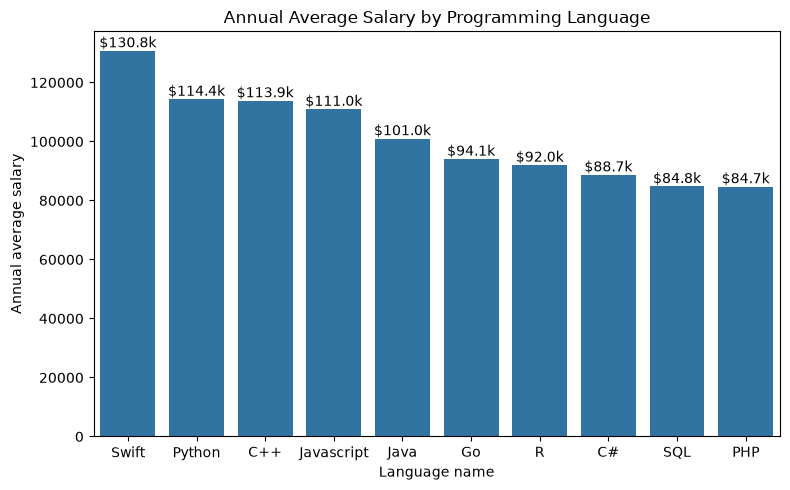

In [35]:
df = df.sort_values(by="Annual average salary", ascending=False)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="Language name",
    y="Annual average salary"
)

ax.bar_label(
    ax.containers[0],
    labels=[f"${v/1000:.1f}k" for v in ax.containers[0].datavalues],
    padding=0
)

plt.title("Annual Average Salary by Programming Language")
plt.tight_layout()
plt.show()

## Authors


Ramesh Sannareddy


### Other Contributors


Rav Ahuja


## Change Log


|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-10-17  | 0.1  | Ramesh Sannareddy  |  Created initial version of the lab |


 Copyright &copy; 2020 IBM Corporation. This notebook and its source code are released under the terms of the [MIT License](https://cognitiveclass.ai/mit-license/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDA0321ENSkillsNetwork928-2022-01-01).
